# Ames Housing: Sale Price Prediction

**Goal:** Compare a range of regression models, from linear models to boosted trees, and identify which predict `SalePrice` most accurately for the Kaggle *House Prices: Advanced Regression Techniques* dataset (Ames, Iowa). Models are tuned with cross-validation and ranked by RMSLE (error on the log scale), with dollar RMSE, MAE and R² on a held-out test set as a check.

**Data:** Kaggle `train.csv`, 1,460 houses. One row with a missing `Electrical` value and two outliers are removed, leaving 1,457 houses, split 80/20 into 1,165 for training and 292 for testing.

**Workflow**

1. Setup and configuration
2. Load data and check missing values
3. Clean missing values
4. Quick EDA: target, correlations, skew
5. Feature engineering, outlier removal and transforms
6. Train/test split
7. Models, search spaces and tuning
8. Compare models
9. Feature importance
10. Stacking check
11. Conclusion and limitations

**How the metrics work**

- The target is `log1p(SalePrice)`, so the models are trained and tuned on the log scale. The scoring metric is `neg_root_mean_squared_error`, i.e. RMSLE (negative because scikit-learn maximises scores).
- For reporting, predictions are converted back to dollars with `np.expm1`. Dollar RMSE, MAE and R² are the test metrics.
- Models are ranked on **cross-validated RMSLE**. The test set has only 292 houses, so it is used as a final check and not for choosing.

## 1. Setup and configuration

In [333]:
# Imports: data handling and plots, scikit-learn tools and models, scipy distributions for the random search, and XGBoost
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import (
    train_test_split, GridSearchCV,RandomizedSearchCV, KFold, cross_val_score
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import ElasticNet, RidgeCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor, AdaBoostRegressor, GradientBoostingRegressor, StackingRegressor
)
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error,r2_score
)
from scipy.stats import randint, uniform, loguniform, skew
from sklearn.pipeline import Pipeline

import xgboost as xgb
from xgboost import  XGBRegressor

from sklearn.base import clone



## 2. Load data and check missing values

Note: pandas reads the text `NA` in the CSV as a missing value. In this dataset `NA` usually means "this house does not have that feature" (no pool, no alley, and so on), so the NaNs are meaningful.

In [269]:
# Read the column descriptions (data_description.txt); printed in the next cell
with open(r"D:\Python files\projects\advanced housing price prediction\data_description.txt") as new_file:
    desc = new_file.read()

In [270]:
print(desc)

MSSubClass: Identifies the type of dwelling involved in the sale.	

        20	1-STORY 1946 & NEWER ALL STYLES
        30	1-STORY 1945 & OLDER
        40	1-STORY W/FINISHED ATTIC ALL AGES
        45	1-1/2 STORY - UNFINISHED ALL AGES
        50	1-1/2 STORY FINISHED ALL AGES
        60	2-STORY 1946 & NEWER
        70	2-STORY 1945 & OLDER
        75	2-1/2 STORY ALL AGES
        80	SPLIT OR MULTI-LEVEL
        85	SPLIT FOYER
        90	DUPLEX - ALL STYLES AND AGES
       120	1-STORY PUD (Planned Unit Development) - 1946 & NEWER
       150	1-1/2 STORY PUD - ALL AGES
       160	2-STORY PUD - 1946 & NEWER
       180	PUD - MULTILEVEL - INCL SPLIT LEV/FOYER
       190	2 FAMILY CONVERSION - ALL STYLES AND AGES

MSZoning: Identifies the general zoning classification of the sale.
		
       A	Agriculture
       C	Commercial
       FV	Floating Village Residential
       I	Industrial
       RH	Residential High Density
       RL	Residential Low Density
       RP	Residential Low Density Park 
       RM

In [271]:
# Load the training data (1,460 rows)
df = pd.read_csv(r"D:\Python files\projects\advanced housing price prediction\train.csv")

In [272]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [273]:
df.columns.sort_values()

Index(['1stFlrSF', '2ndFlrSF', '3SsnPorch', 'Alley', 'BedroomAbvGr',
       'BldgType', 'BsmtCond', 'BsmtExposure', 'BsmtFinSF1', 'BsmtFinSF2',
       'BsmtFinType1', 'BsmtFinType2', 'BsmtFullBath', 'BsmtHalfBath',
       'BsmtQual', 'BsmtUnfSF', 'CentralAir', 'Condition1', 'Condition2',
       'Electrical', 'EnclosedPorch', 'ExterCond', 'ExterQual', 'Exterior1st',
       'Exterior2nd', 'Fence', 'FireplaceQu', 'Fireplaces', 'Foundation',
       'FullBath', 'Functional', 'GarageArea', 'GarageCars', 'GarageCond',
       'GarageFinish', 'GarageQual', 'GarageType', 'GarageYrBlt', 'GrLivArea',
       'HalfBath', 'Heating', 'HeatingQC', 'HouseStyle', 'Id', 'KitchenAbvGr',
       'KitchenQual', 'LandContour', 'LandSlope', 'LotArea', 'LotConfig',
       'LotFrontage', 'LotShape', 'LowQualFinSF', 'MSSubClass', 'MSZoning',
       'MasVnrArea', 'MasVnrType', 'MiscFeature', 'MiscVal', 'MoSold',
       'Neighborhood', 'OpenPorchSF', 'OverallCond', 'OverallQual',
       'PavedDrive', 'PoolArea', 'Po

In [274]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


## 3. Clean missing values

In this dataset a missing value usually means "the house does not have that feature". Each fill below follows a check on the data, and the output of that check is shown in the cell.

| Columns | What the check showed | Action |
|---|---|---|
| `PoolQC`, `MiscFeature` | 99.5% and 96.3% missing | Dropped. The `Has_PoolArea` and `Has_MiscVal` flags (section 5) keep the information |
| `Alley`, `Fence`, `MasVnrType` | NaN means the feature does not exist | `'NA'` category |
| `FireplaceQu` | All 690 missing rows have `Fireplaces = 0` | `'NA'` category |
| `GarageType`, `GarageFinish`, `GarageQual`, `GarageCond`, `GarageYrBlt` | All 81 houses with a missing garage column have `GarageArea = 0` | `'NA'` category; `0` for `GarageYrBlt` |
| `BsmtExposure`, `BsmtFinType1/2`, `BsmtQual`, `BsmtCond` | NaN means no basement (37 to 38 houses) | `'NA'` category |
| `MasVnrArea` | The 8 missing rows all have `MasVnrType` = `'NA'` | `0` |
| `Electrical` | 1 missing row | Row dropped |
| `LotFrontage` | 259 missing (17.7%). Frontage differs by building type and neighbourhood | Filled in section 5, using training rows only |

In [275]:
# Helper: columns with missing values (count and percent), largest first
def null_df(df):
    nullc = df.isnull().sum()
    nullp = round(100 * df.isnull().sum()/len(df),2)
    na = pd.DataFrame({'Null Count':nullc, 'Null percent':nullp})
    na = na[na['Null Count'] >0]

    return na.sort_values('Null Count', ascending = False )

In [276]:
# Missing values at the start. PoolQC (99.5%), MiscFeature (96.3%), Alley (93.8%) and Fence (80.8%) are almost entirely missing
null_df(df)

,Null Count,Null percent
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


<Axes: xlabel='PoolQC', ylabel='SalePrice'>

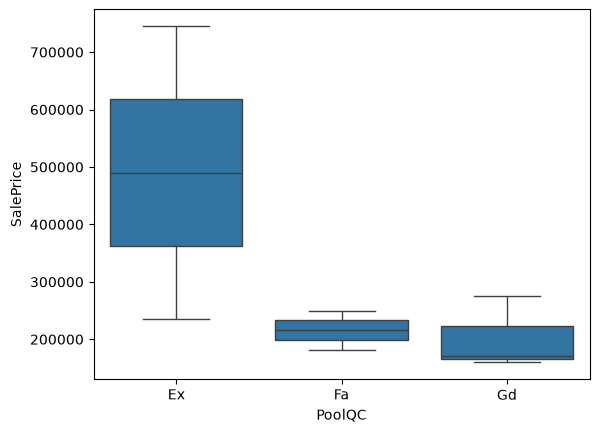

In [277]:
# SalePrice by PoolQC, to look at the pool column before deciding what to do with it
sns.boxplot(data = df, x = 'PoolQC', y = 'SalePrice')

In [278]:
# PoolQC and MiscFeature are almost entirely missing, so both are dropped. Pool and misc information is still kept through the Has_PoolArea and Has_MiscVal flags created in section 5
df = df.drop(['PoolQC','MiscFeature'], axis = 1 )

In [279]:
# Missing values after dropping those two columns
null_df(df)

,Null Count,Null percent
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55
GarageQual,81,5.55
GarageCond,81,5.55


In [280]:
# Alley has only two real values (Grvl and Pave); every other house is NaN
df['Alley'].value_counts()

Alley
Grvl    50
Pave    41
Name: count, dtype: int64

In [281]:
# For Alley, Fence and MasVnrType, NaN means the feature does not exist, so it becomes an explicit 'NA' category
df[['Alley','Fence','MasVnrType']] = df[['Alley','Fence','MasVnrType']].fillna('NA')

In [282]:
# Missing values after the fill
null_df(df)

,Null Count,Null percent
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageYrBlt,81,5.55
GarageFinish,81,5.55
GarageType,81,5.55
GarageQual,81,5.55
GarageCond,81,5.55
BsmtExposure,38,2.60
BsmtFinType2,38,2.60
BsmtCond,37,2.53


In [283]:
# Every house with a missing FireplaceQu has 0 fireplaces, so NaN means 'no fireplace'
df[df['FireplaceQu'].isna()]['Fireplaces'].value_counts()

Fireplaces
0    690
Name: count, dtype: int64

In [284]:
# Fill missing FireplaceQu with 'NA' (no fireplace)
df['FireplaceQu'] = df['FireplaceQu'].fillna('NA')

In [285]:
# Missing values after the fill
null_df(df)

,Null Count,Null percent
LotFrontage,259,17.74
GarageYrBlt,81,5.55
GarageFinish,81,5.55
GarageQual,81,5.55
GarageType,81,5.55
GarageCond,81,5.55
BsmtFinType2,38,2.60
BsmtExposure,38,2.60
BsmtQual,37,2.53
BsmtFinType1,37,2.53


In [286]:
# Every house with a missing garage column has GarageArea = 0 (81 houses), so NaN means 'no garage'
df[(df['GarageYrBlt'].isna()) | (df['GarageFinish'].isna()) | (df['GarageQual'].isna()) | (df['GarageType'].isna()) | (df['GarageCond'].isna())
    ]['GarageArea'].value_counts()

GarageArea
0    81
Name: count, dtype: int64

In [287]:
# No garage: 'NA' category for the text columns, and 0 for GarageYrBlt (a placeholder used later to build Has_Garage and GarageAge)
df[['GarageQual','GarageFinish','GarageType','GarageCond']] = df[['GarageQual','GarageFinish','GarageType','GarageCond']].fillna('NA')
df['GarageYrBlt'] = df['GarageYrBlt'].fillna(0)

In [288]:
# Basement columns: NaN means 'no basement', so it becomes an explicit 'NA' category
df[['BsmtExposure','BsmtFinType2','BsmtQual','BsmtFinType1','BsmtCond']] = df[['BsmtExposure','BsmtFinType2','BsmtQual','BsmtFinType1','BsmtCond']].fillna('NA')

In [289]:
# Missing values after the fill
null_df(df)

,Null Count,Null percent
LotFrontage,259,17.74
MasVnrArea,8,0.55
Electrical,1,0.07


In [290]:
# The 8 houses with a missing MasVnrArea all have MasVnrType 'NA' (no masonry veneer)
df[df['MasVnrArea'].isna()]['MasVnrType'].value_counts()

MasVnrType
NA    8
Name: count, dtype: int64

In [291]:
# No veneer, so the area is 0
df['MasVnrArea'] = df['MasVnrArea'].fillna(0)

In [292]:
# Drop the single row with a missing Electrical value
df = df.dropna(subset=['Electrical'], axis=0)

In [293]:
# Missing values after the fill
null_df(df)

,Null Count,Null percent
LotFrontage,259,17.75


In [294]:
# First rows of the houses with a missing LotFrontage
df[df['LotFrontage'].isna()].head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,3SsnPorch,ScreenPorch,PoolArea,Fence,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
7,8,60,RL,NaN,10382,Pave,NA,IR1,Lvl,AllPub,...,0,0,0,NA,350,11,2009,WD,Normal,200000
12,13,20,RL,NaN,12968,Pave,NA,IR2,Lvl,AllPub,...,0,176,0,NA,0,9,2008,WD,Normal,144000
14,15,20,RL,NaN,10920,Pave,NA,IR1,Lvl,AllPub,...,0,0,0,GdWo,0,5,2008,WD,Normal,157000
16,17,20,RL,NaN,11241,Pave,NA,IR1,Lvl,AllPub,...,0,0,0,NA,700,3,2010,WD,Normal,149000
24,25,20,RL,NaN,8246,Pave,NA,IR1,Lvl,AllPub,...,0,0,0,MnPrv,0,5,2010,WD,Normal,154000


In [295]:
# Building types of the houses with a missing LotFrontage (mostly 1Fam)
df[df['LotFrontage'].isna()]['BldgType'].value_counts()

BldgType
1Fam      226
TwnhsE     22
Duplex      5
Twnhs       3
2fmCon      3
Name: count, dtype: int64

In [296]:
# Correlation of LotFrontage with the other numeric columns
df.corr(numeric_only = True)['LotFrontage'].sort_values()

MSSubClass      -0.386448
OverallCond     -0.059168
Id              -0.010769
BsmtHalfBath    -0.007211
KitchenAbvGr    -0.006046
MiscVal          0.003381
YrSold           0.007435
EnclosedPorch    0.010738
MoSold           0.011251
LowQualFinSF     0.038482
ScreenPorch      0.041411
BsmtFinSF2       0.049930
HalfBath         0.053440
3SsnPorch        0.070041
2ndFlrSF         0.080125
WoodDeckSF       0.088513
YearRemodAdd     0.088801
BsmtFullBath     0.101056
GarageYrBlt      0.105210
YearBuilt        0.123301
BsmtUnfSF        0.132703
OpenPorchSF      0.152074
MasVnrArea       0.192492
FullBath         0.198741
PoolArea         0.206176
BsmtFinSF1       0.233810
OverallQual      0.251793
BedroomAbvGr     0.263158
Fireplaces       0.266826
GarageCars       0.285673
GarageArea       0.345047
SalePrice        0.351821
TotRmsAbvGrd     0.352081
TotalBsmtSF      0.392601
GrLivArea        0.402830
LotArea          0.426101
1stFlrSF         0.457499
LotFrontage      1.000000
Name: LotFro

In [297]:
# Average LotFrontage by building type (Twnhs is about 25 ft, 1Fam about 75 ft)
df.groupby('BldgType')['LotFrontage'].mean().sort_values()

BldgType
Twnhs     24.675000
TwnhsE    41.978261
2fmCon    66.428571
Duplex    71.595745
1Fam      74.504532
Name: LotFrontage, dtype: float64

In [298]:
# Average LotFrontage by neighbourhood
df.groupby('Neighborhood')['LotFrontage'].mean().sort_values()

Neighborhood
BrDale     21.562500
Blueste    24.000000
MeadowV    27.800000
NPkVill    32.285714
Blmngtn    47.142857
BrkSide    57.509804
SWISU      58.913043
Veenker    59.714286
IDOTRR     62.500000
StoneBr    62.700000
OldTown    62.788991
Somerst    64.666667
Edwards    68.217391
Mitchel    70.083333
SawyerW    71.500000
CollgCr    71.682540
Crawfor    71.804878
Sawyer     74.437500
NAmes      76.462366
Gilbert    79.877551
Timber     80.379310
NWAmes     81.288889
NridgHt    81.881579
ClearCr    83.461538
NoRidge    91.878788
Name: LotFrontage, dtype: float64

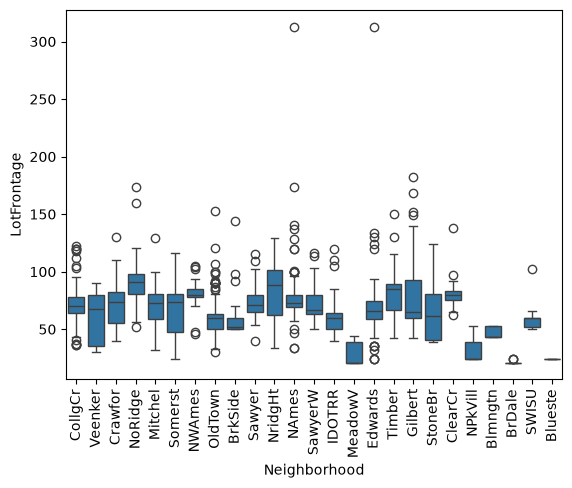

In [299]:
# Spread of LotFrontage within each neighbourhood. Frontage depends on building type and neighbourhood, which is why both are used for the fill
sns.boxplot(data =df, x = 'Neighborhood', y= 'LotFrontage')
plt.xticks(rotation = 90);

In [300]:
# LotFrontage is still missing here (259 values). It is filled in the cell that starts with train_idx, further down
null_df(df)

,Null Count,Null percent
LotFrontage,259,17.75


In [301]:
# Correlation of each numeric column with SalePrice
df.corr(numeric_only = True)['SalePrice'].sort_values()[:-1]

KitchenAbvGr    -0.135935
EnclosedPorch   -0.128627
MSSubClass      -0.084230
OverallCond     -0.077924
YrSold          -0.028907
LowQualFinSF    -0.025620
Id              -0.021756
MiscVal         -0.021200
BsmtHalfBath    -0.016873
BsmtFinSF2      -0.011412
3SsnPorch        0.044571
MoSold           0.046380
PoolArea         0.092397
ScreenPorch      0.111419
BedroomAbvGr     0.168235
BsmtUnfSF        0.214446
BsmtFullBath     0.227082
GarageYrBlt      0.261413
LotArea          0.263837
HalfBath         0.284400
OpenPorchSF      0.315831
2ndFlrSF         0.319464
WoodDeckSF       0.324422
LotFrontage      0.351821
BsmtFinSF1       0.386436
Fireplaces       0.466968
MasVnrArea       0.472606
YearRemodAdd     0.507430
YearBuilt        0.523273
TotRmsAbvGrd     0.533779
FullBath         0.560881
1stFlrSF         0.605968
TotalBsmtSF      0.613905
GarageArea       0.623423
GarageCars       0.640473
GrLivArea        0.708618
OverallQual      0.791069
Name: SalePrice, dtype: float64

## 4. Quick EDA: target, correlations, skew

A right-skewed target (a few very expensive houses) hurts models trained on squared error. `SalePrice` has a skew of about 1.88 before the transform (see the skew list in section 5), which is why the target is log-transformed. The correlation list below shows which numeric columns relate most to the price.

In [302]:
# for c in num_cols:
#     fig, ax = plt.subplots(1, 3, figsize=(14,3))
#     sns.histplot(df[c], kde=True, ax=ax[0])          # shape
#     sns.boxplot(x=df[c], ax=ax[1]);                   # outliers / tail

## 5. Feature engineering, outlier removal and transforms

The steps run as separate cells, in this order. Run them once, top to bottom (the log transforms would be applied twice if a cell is run again).

| Step | What was done | Why |
|---|---|---|
| 1. Flags | `Has_*` flags for 13 mostly-zero columns (porches, pool, misc value, second floor, veneer, and others) and `MultiKitchen` | "Has a porch at all" is informative on its own, and the size column is mostly zeros |
| 2. Garage and ages | `Has_Garage`; `GarageAge` (sale year minus garage year, or -1 with no garage); `HouseAge`; `RemodAge` | Ages are comparable across sale years |
| 3. Derived features | `RemodDone`, `TotalNumBathrooms`, `TotRoomsInclBath`, `AvgRoomSize` | Totals and ratios built from the raw columns |
| 4. Interactions | `QualityxSize` (quality x living area) and `QualityxCond` (quality x condition) | Gives the linear models an interaction directly |
| 5. Ordinal encoding | 18 quality, condition and finish columns mapped to numbers (`<column>_map`) | These columns have a natural order that one-hot encoding would lose |
| 6. Outliers | Two houses removed: large (`QualityxSize` > 40000) and cheaper than $300,000 | Both are in Edwards, with a very large `QualityxSize` but a price under $300,000 |
| 7. LotFrontage | Missing values filled with the (building type, neighbourhood) mean, then the neighbourhood median, both computed from training rows only | Avoids using the test rows to fill training features |
| 8. Log transforms | `log1p` of the target and of 16 skewed size columns | Pulls in long right tails |

The derived features and interactions are built before the log transform, so they use the raw `GrLivArea`.

In [303]:
# Flag columns: 1 if the house has the feature (value > 0). These columns are mostly 0. Created before the log transform, while zeros are still zeros. MultiKitchen = more than one kitchen
flag_cols = ["MiscVal","PoolArea","3SsnPorch","LowQualFinSF","BsmtFinSF2",
             "ScreenPorch","EnclosedPorch","MasVnrArea","WoodDeckSF",
             "OpenPorchSF","2ndFlrSF","BsmtFinSF1","BsmtHalfBath"]
for c in flag_cols:
    df[f"Has_{c}"] = (df[c] > 0).astype(int)

df["MultiKitchen"] = (df["KitchenAbvGr"] > 1).astype(int)

In [304]:
# Has_Garage: 1 if the house has a garage (GarageYrBlt was filled with 0 for houses without one)
df["Has_Garage"] = (df['GarageYrBlt']>0).astype(int)

In [305]:
# GarageAge = sale year - garage year built for houses with a garage, -1 for houses without one. HouseAge and RemodAge = years since built / remodelled at the time of sale. MSSubClass is treated as a category. The raw year columns, Id, PoolArea and MiscVal are dropped (the flags above keep the PoolArea and MiscVal information)
age = df["YrSold"] - df["GarageYrBlt"]
df["GarageAge"] = np.where(df['Has_Garage'], age, -1)


df["HouseAge"]  = df["YrSold"] - df["YearBuilt"]
df["RemodAge"]  = df["YrSold"] - df["YearRemodAdd"]

df["MSSubClass"] = df["MSSubClass"].astype(str)
df = df.drop(["GarageYrBlt", "PoolArea", "MiscVal", "Id", "YearBuilt", "YearRemodAdd"], axis = 1 )

In [306]:
# Print the data description again for reference
print(desc)

MSSubClass: Identifies the type of dwelling involved in the sale.	

        20	1-STORY 1946 & NEWER ALL STYLES
        30	1-STORY 1945 & OLDER
        40	1-STORY W/FINISHED ATTIC ALL AGES
        45	1-1/2 STORY - UNFINISHED ALL AGES
        50	1-1/2 STORY FINISHED ALL AGES
        60	2-STORY 1946 & NEWER
        70	2-STORY 1945 & OLDER
        75	2-1/2 STORY ALL AGES
        80	SPLIT OR MULTI-LEVEL
        85	SPLIT FOYER
        90	DUPLEX - ALL STYLES AND AGES
       120	1-STORY PUD (Planned Unit Development) - 1946 & NEWER
       150	1-1/2 STORY PUD - ALL AGES
       160	2-STORY PUD - 1946 & NEWER
       180	PUD - MULTILEVEL - INCL SPLIT LEV/FOYER
       190	2 FAMILY CONVERSION - ALL STYLES AND AGES

MSZoning: Identifies the general zoning classification of the sale.
		
       A	Agriculture
       C	Commercial
       FV	Floating Village Residential
       I	Industrial
       RH	Residential High Density
       RL	Residential Low Density
       RP	Residential Low Density Park 
       RM

In [307]:
# Lets add derived features such as total area,age, total no of rooms, total no of bedrooms, avg room size
df['RemodDone'] = np.where((df['RemodAge'] != df['HouseAge']),1,0)
df['TotalNumBathrooms'] = (
    df['FullBath'] + (0.5 * df['HalfBath']) +
    df['BsmtFullBath'] + (0.5 * df['BsmtHalfBath'])
)
df['TotRoomsInclBath'] = df['TotRmsAbvGrd'] + df['TotalNumBathrooms']
df['AvgRoomSize'] = df['GrLivArea'] / df['TotRoomsInclBath']


In [308]:
# Interaction features: overall quality x living area, and overall quality x overall condition. Built before the log transform, so QualityxSize uses the raw GrLivArea
df['QualityxSize'] = df['GrLivArea'] * df['OverallQual']
df['QualityxCond'] = df['OverallCond'] * df['OverallQual']

In [309]:
# Spread of the numeric columns (min, 1%, median, 99%, max) to spot extreme values
df.describe(percentiles=[.01, .05, .5, .95, .99]).T[["min","1%","50%","99%","max"]]

,min,1%,50%,99%,max
LotFrontage,21.000000,21.0000,69.000000,141.030000,313.000000
LotArea,1300.000000,1680.0000,9477.000000,37593.680000,215245.000000
OverallQual,1.000000,3.0000,6.000000,10.000000,10.000000
OverallCond,1.000000,3.0000,5.000000,9.000000,9.000000
MasVnrArea,0.000000,0.0000,0.000000,791.360000,1600.000000
BsmtFinSF1,0.000000,0.0000,384.000000,1572.420000,5644.000000
BsmtFinSF2,0.000000,0.0000,0.000000,830.560000,1474.000000
BsmtUnfSF,0.000000,0.0000,479.000000,1797.100000,2336.000000
TotalBsmtSF,0.000000,0.0000,992.000000,2155.100000,6110.000000
1stFlrSF,334.000000,520.0000,1088.000000,2219.520000,4692.000000


In [310]:
# Ordinal encoding: these 18 columns have a natural order, so each text value is mapped to a number (for example Po=1 ... Ex=5, with NA=0). The numeric versions are new columns named <column>_map
ordinal_maps = {
    "ExterQual": {"NA": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "ExterCond": {"NA": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "BsmtQual":{"NA": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "BsmtCond":{"NA": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "HeatingQC":{"NA": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "KitchenQual":{"NA": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "FireplaceQu":{"NA": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "GarageQual":{"NA": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5},
    "GarageCond":{"NA": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}, 
    "BsmtExposure": {"NA": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4},
    "BsmtFinType1": {"NA": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "BsmtFinType2": {"NA": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "GarageFinish": {"NA": 0, "Unf": 1, "RFn": 2, "Fin": 3},
    "LandSlope":    {"Sev": 1, "Mod": 2, "Gtl": 3},
    "PavedDrive":   {"N": 0, "P": 1, "Y": 2},
    "CentralAir":   {"N": 0, "Y": 1},
    "LotShape":     {"IR3": 1, "IR2": 2, "IR1": 3, "Reg": 4},
    "Functional":   {"Sal": 1, "Sev": 2, "Maj2": 3, "Maj1": 4, "Mod": 5, "Min2": 6, "Min1": 7, "Typ": 8},
}

df_ord = df.copy()

for col, mapping in ordinal_maps.items():
   df[f"{col}_map"] = df[col].map(mapping)

In [311]:
# Drop the original text versions of the ordinal columns; only the _map columns are kept
df = df.drop(columns=list(ordinal_maps)) 

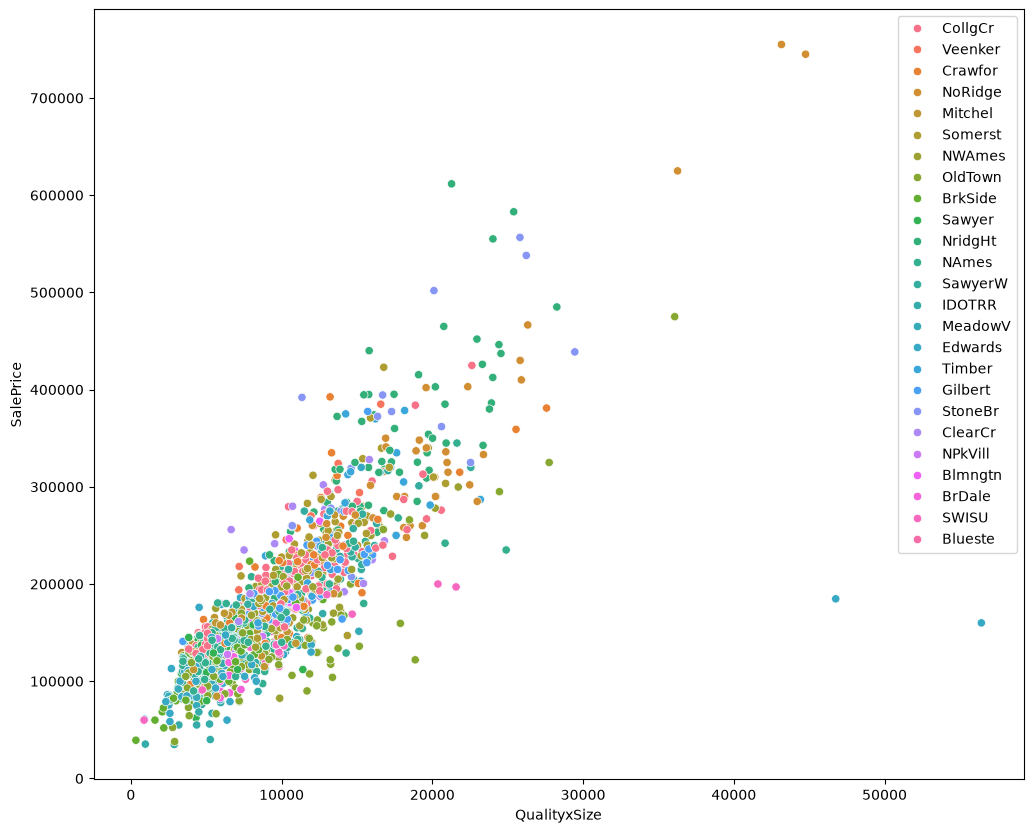

In [312]:
# QualityxSize against SalePrice, coloured by neighbourhood, to look for outliers
plt.figure(figsize = (12,10))
sns.scatterplot(df, x= 'QualityxSize', y= 'SalePrice', hue = 'Neighborhood')
plt.legend(bbox_to_anchor = (1,1))

In [313]:
# Houses with a very large QualityxSize (> 40000) but a SalePrice below $300,000: two houses (index 523 and 1298, both in Edwards)
df[(df['QualityxSize'] > 40000) & (df ['SalePrice'] <300000)]

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LandContour,Utilities,LotConfig,Neighborhood,...,GarageCond_map,BsmtExposure_map,BsmtFinType1_map,BsmtFinType2_map,GarageFinish_map,LandSlope_map,PavedDrive_map,CentralAir_map,LotShape_map,Functional_map
523,60,RL,130.0,40094,Pave,NA,Bnk,AllPub,Inside,Edwards,...,3,4,6,1,3,3,2,1,3,8
1298,60,RL,313.0,63887,Pave,NA,Bnk,AllPub,Corner,Edwards,...,3,4,6,1,3,3,2,1,1,8


In [314]:
# Remove those two houses. The whole condition sits inside one pair of parentheses, so only houses that are BOTH large (QualityxSize > 40000) AND cheaper than $300,000 are dropped. (An earlier version of this line, without the outer parentheses, dropped every house priced at $300,000 or more)
df = df[~((df['QualityxSize'] > 40000) & (df ['SalePrice'] <300000))]

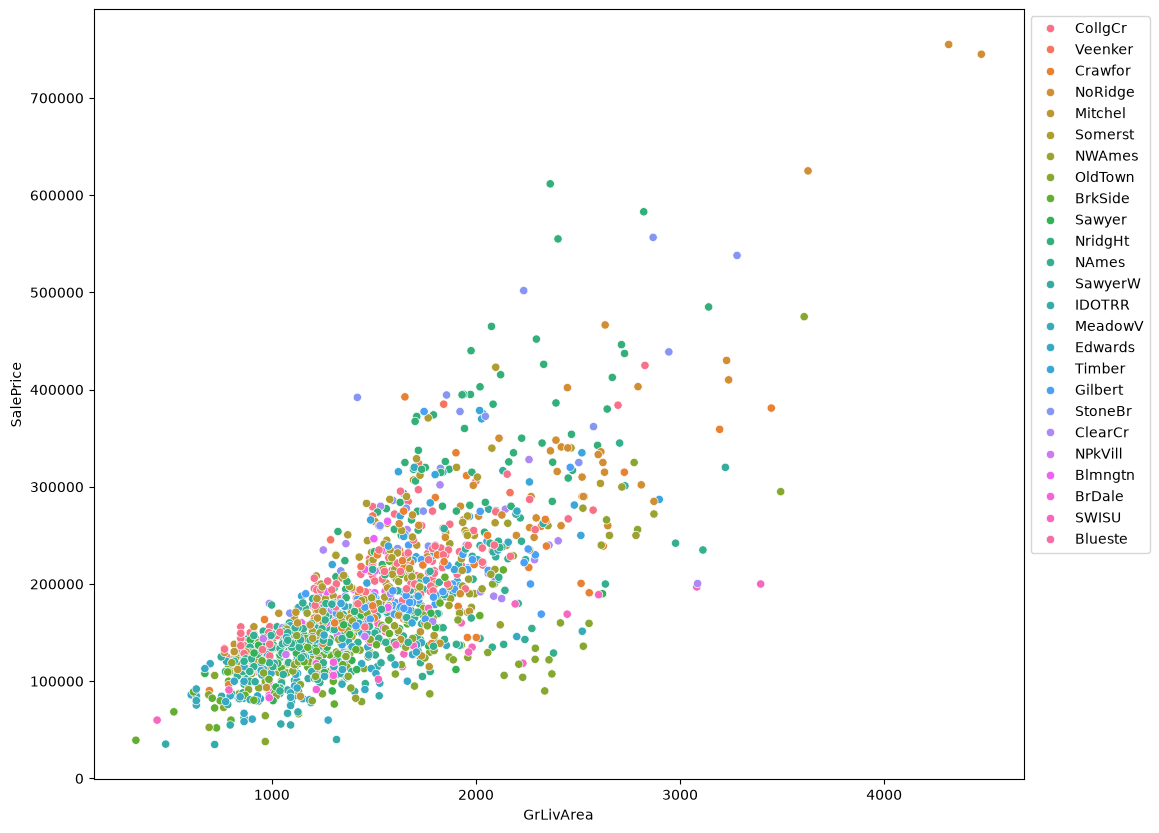

In [315]:
# GrLivArea against SalePrice after the removal
plt.figure(figsize = (12,10))
sns.scatterplot(df, x= 'GrLivArea', y= 'SalePrice', hue = 'Neighborhood')
plt.legend(bbox_to_anchor = (1,1))

In [316]:
# One more large, cheaper house was looked at (index 1031: GrLivArea > 3000, price < $200,000; OverallQual 7, OverallCond 3). It was kept
df[(df['GrLivArea'] > 3000) & (df ['SalePrice'] <200000)][['OverallQual','OverallCond']]

,OverallQual,OverallCond
1031,7,3


In [317]:
# LotFrontage fill using TRAINING rows only. train_idx are the rows that end up in the training set (same split settings as the later split). The (BldgType, Neighborhood) mean and the neighbourhood median are computed from those rows only, then used to fill the missing values in all rows
train_idx, test_idx = train_test_split(df.index, test_size=0.2, random_state=42)
train_part = df.loc[train_idx]

grp_mean = train_part.groupby(["BldgType", "Neighborhood"])["LotFrontage"].mean()
nb_median = train_part.groupby("Neighborhood")["LotFrontage"].median()

key = pd.MultiIndex.from_frame(df[["BldgType", "Neighborhood"]])
fill = pd.Series(grp_mean.reindex(key).values, index=df.index)
fill = fill.fillna(df["Neighborhood"].map(nb_median))
df["LotFrontage"] = df["LotFrontage"].fillna(fill)

In [319]:
# Skewness of every numeric column (before the log transforms)
num_cols = df.select_dtypes(exclude='object').columns
skews = df[num_cols].apply(skew).sort_values(key=abs, ascending=False)
print(skews)

Has_PoolArea       15.486687
LotArea            12.556596
3SsnPorch          10.282886
LowQualFinSF        8.992490
Has_3SsnPorch       7.597702
                     ...    
FireplaceQu_map     0.114185
YrSold              0.095574
RemodDone           0.094822
Has_WoodDeckSF      0.089313
FullBath            0.032539
Length: 73, dtype: float64


In [320]:
# Columns with skew above 1. Most are Has_ flags or small-count columns, which a transform cannot fix. The continuous size columns are log-transformed below. SalePrice (1.88) is log-transformed as the target. QualityxSize (1.49) is left as it is
skews[skews > 1]

Has_PoolArea         15.486687
LotArea              12.556596
3SsnPorch            10.282886
LowQualFinSF          8.992490
Has_3SsnPorch         7.597702
Has_LowQualFinSF      7.283998
Has_MiscVal           5.005621
KitchenAbvGr          4.478508
MultiKitchen          4.335259
BsmtFinSF2            4.245879
ScreenPorch           4.113045
BsmtHalfBath          4.094248
Has_BsmtHalfBath      3.850705
BsmtFinType2_map      3.289337
Has_ScreenPorch       3.105937
EnclosedPorch         3.082631
MasVnrArea            2.692486
Has_BsmtFinSF2        2.419506
OpenPorchSF           2.336612
Has_EnclosedPorch     2.042386
SalePrice             1.878426
WoodDeckSF            1.543785
QualityxSize          1.491221
LotFrontage           1.425493
ExterCond_map         1.393150
BsmtExposure_map      1.105308
GrLivArea             1.009196
dtype: float64

In [321]:
# Log-transform the target: log1p(SalePrice). Models are trained on this scale, and predictions are converted back with expm1 for the dollar metrics. Run this cell only once
df["SalePrice"] = np.log1p(df["SalePrice"])

In [322]:
# log1p of the skewed size columns (after the Has_ flags and derived features were built). Run this cell only once
log_cols = ["LotArea","LotFrontage","GrLivArea","1stFlrSF","TotalBsmtSF","BsmtFinSF1",
            "BsmtUnfSF","2ndFlrSF","MasVnrArea","OpenPorchSF","WoodDeckSF",
            "BsmtFinSF2","ScreenPorch","EnclosedPorch","3SsnPorch","LowQualFinSF"]
df[log_cols] = np.log1p(df[log_cols])

## 6. Train/test split

One-hot encoding turns the remaining text columns into 0/1 columns, and `drop_first=True` removes one redundant column per category. No scaling is done here: the `StandardScaler` sits **inside each model's Pipeline**, so during cross-validation it is fitted on the training folds only.

*Small Limitation* - The `LotFrontage` fill values were computed once from the full training set, not again inside each cross-validation fold.

In [323]:
# One-hot encode the remaining text columns (drop_first=True). x = features, y = log price
x = pd.get_dummies(df.drop('SalePrice', axis =1), drop_first = True)
y = df['SalePrice']

In [324]:
# 80/20 train/test split (random_state=42)
X_train, X_test, y_train_log, y_test_log = train_test_split(x, y, test_size=0.2, random_state=42)

In [335]:
#Verifying if the train split used to populate Lot Frontage is similar to the train set for fitting the models
assert set(X_train.index) == set(train_idx)

## 7. Models, search spaces and tuning

- **Small spaces use `GridSearchCV`** (every combination is tried): ElasticNet, KNN, SVR and Decision Tree.
- **Large spaces use `RandomizedSearchCV`** (30 random draws each): Random Forest, AdaBoost, Gradient Boosting and XGBoost. `randint(a, b)` draws integers `a..b-1`, `uniform(start, width)` draws from `[start, start+width]`, and `loguniform(a, b)` samples evenly on a log scale (right for learning rates and penalties).
- Every model is a `Pipeline([scaler, model])`. Scaling matters for ElasticNet, KNN and SVR. It does nothing useful for the tree models but is harmless, so one structure is used throughout.
- All searches use the same shuffled 5-fold split (`KFold(5, shuffle=True, random_state=42)`), and the random search is seeded with `random_state=42`.
- Several tuning rounds were run while learning. The parameters and results shown below are from the final run.

In [325]:
# Models and search spaces. Each model is a Pipeline of StandardScaler + model, so scaling is fitted inside each CV fold. Parameter names start with mod__ (the model step)
models = { 'ElasticNet':(Pipeline([('scaler',StandardScaler()), ('mod',ElasticNet(max_iter = 50000))]), {'mod__alpha':np.logspace(-4, 2, 30), 'mod__l1_ratio':[0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0]}),
           'KNN':(Pipeline([('scaler',StandardScaler()), ('mod',KNeighborsRegressor(n_jobs = -1))]), {'mod__n_neighbors':np.arange(1,11)}),
           'SVR':(Pipeline([('scaler',StandardScaler()), ('mod',SVR())]), {'mod__C':[0.01,0.1,1,10,100], 'mod__kernel':['rbf','poly'],'mod__gamma':['auto','scale'], 'mod__degree':[2,3,4], 'mod__epsilon':[0.01,0.05,0.1]}),
           'DT':(Pipeline([('scaler',StandardScaler()), ('mod', DecisionTreeRegressor())]), {'mod__max_depth':np.arange(3,30),'mod__min_samples_leaf':np.arange(1,20)}),                                                                
           'RF':(Pipeline([('scaler',StandardScaler()), ('mod', RandomForestRegressor())]), {'mod__n_estimators':randint(100,600), 'mod__max_features': uniform(0.1, 0.4),'mod__min_samples_leaf':np.arange(2,20),'mod__max_depth':np.arange(2,20)}),                                                              
           'ADA':(Pipeline([('scaler',StandardScaler()), ('mod', AdaBoostRegressor(estimator = DecisionTreeRegressor()))]), {'mod__n_estimators':randint(300,1000),'mod__learning_rate':loguniform(0.02, 0.4), 'mod__estimator__min_samples_leaf':np.arange(2,30),'mod__estimator__max_depth':np.arange(2,8)}),                                                              
           'GB':(Pipeline([('scaler',StandardScaler()), ('mod', GradientBoostingRegressor())]), {'mod__n_estimators':randint(300,1500),'mod__learning_rate':loguniform(0.02, 0.4), 'mod__min_samples_leaf':np.arange(2,30,),'mod__max_depth':np.arange(2,15)}) ,                                                           
           'XGB':(Pipeline([('scaler',StandardScaler()), ('mod', XGBRegressor(tree_method='hist', random_state=101, n_jobs=1))]), {'mod__n_estimators': randint(300, 1500),
                   'mod__learning_rate':    loguniform(0.01, 0.1),
                   'mod__max_depth':        randint(2, 6),
                   'mod__min_child_weight': randint(1, 11),
                   'mod__subsample':        uniform(0.6, 0.4),
                   'mod__colsample_bytree': uniform(0.3, 0.7),
                   'mod__reg_lambda':       loguniform(0.5, 20),
                   'mod__reg_alpha':        loguniform(1e-3, 1)})

}

In [326]:
# Tuning loop. GridSearchCV for ElasticNet, KNN, SVR and DT; RandomizedSearchCV with 30 draws for RF, ADA, GB and XGB. 
# All searches use the same shuffled 5-fold KFold (seed 42) and score by RMSE on the log price (RMSLE). For each model it stores the best parameters and pipeline, the CV score and its std across folds, the test metrics, and the coefficients or feature importances

best_params, best_models,features_imp, rows = {},{},{},[]

large = {'RF','ADA','GB','XGB'}
cv = KFold(5, shuffle=True, random_state=42)   

def evaluate(y_true_log, pred_log):
    y_true, pred = np.expm1(y_true_log), np.expm1(pred_log)
    rmse = np.sqrt(mean_squared_error(y_true, pred))
    return {"test_rmsle": np.sqrt(mean_squared_error(y_true_log, pred_log)),
            "test_rmse": rmse,
            "test_mae": mean_absolute_error(y_true, pred),
            "test_r2": r2_score(y_true, pred)}


for name,(pipe,grid) in models.items():
    if name in large:
         gs = RandomizedSearchCV(pipe, grid,cv=cv,random_state = 42, n_iter=30,verbose =2,
                                scoring="neg_root_mean_squared_error", n_jobs=-1)
    else:
        gs = GridSearchCV(pipe,grid,scoring="neg_root_mean_squared_error",cv=cv, n_jobs=-1,verbose =2)
    
    gs.fit(X_train,y_train_log)
    y_pred_log = gs.predict(X_test)

    best_params[name] = gs.best_params_
    best_models[name] = gs.best_estimator_
    rows.append({"model": name,
                 "cv_rmsle": -gs.best_score_,
                 "cv_std": gs.cv_results_["std_test_score"][gs.best_index_],
                 **evaluate(y_test_log, y_pred_log)
                 })
 
    model = gs.best_estimator_.named_steps["mod"]      # the model inside the pipeline
    if hasattr(model, "coef_"):
        features_imp[name] = pd.Series(np.ravel(model.coef_), index=X_train.columns)
    elif hasattr(model, "feature_importances_"):
        features_imp[name] = pd.Series(model.feature_importances_, index=X_train.columns)
    else:
        features_imp[name] = None  
    print(f'{name} completed')     

Fitting 5 folds for each of 300 candidates, totalling 1500 fits
ElasticNet completed
Fitting 5 folds for each of 10 candidates, totalling 50 fits
KNN completed
Fitting 5 folds for each of 180 candidates, totalling 900 fits
SVR completed
Fitting 5 folds for each of 513 candidates, totalling 2565 fits
DT completed
Fitting 5 folds for each of 30 candidates, totalling 150 fits
RF completed
Fitting 5 folds for each of 30 candidates, totalling 150 fits
ADA completed
Fitting 5 folds for each of 30 candidates, totalling 150 fits
GB completed
Fitting 5 folds for each of 30 candidates, totalling 150 fits
XGB completed


In [327]:
# Best parameters found for each model
best_params

{'ElasticNet': {'mod__alpha': np.float64(0.004520353656360241),
  'mod__l1_ratio': 0.9},
 'KNN': {'mod__n_neighbors': np.int64(6)},
 'SVR': {'mod__C': 10,
  'mod__degree': 3,
  'mod__epsilon': 0.01,
  'mod__gamma': 'auto',
  'mod__kernel': 'poly'},
 'DT': {'mod__max_depth': np.int64(29), 'mod__min_samples_leaf': np.int64(8)},
 'RF': {'mod__max_depth': np.int64(19),
  'mod__max_features': np.float64(0.36500891374159283),
  'mod__min_samples_leaf': np.int64(3),
  'mod__n_estimators': 489},
 'ADA': {'mod__estimator__max_depth': np.int64(7),
  'mod__estimator__min_samples_leaf': np.int64(5),
  'mod__learning_rate': np.float64(0.11992667764825322),
  'mod__n_estimators': 570},
 'GB': {'mod__learning_rate': np.float64(0.02127213302508057),
  'mod__max_depth': np.int64(3),
  'mod__min_samples_leaf': np.int64(25),
  'mod__n_estimators': 1105},
 'XGB': {'mod__colsample_bytree': np.float64(0.47088786557344187),
  'mod__learning_rate': np.float64(0.014732995024087009),
  'mod__max_depth': 5,
  'm

## 8. Compare models

Models are ranked by **CV RMSLE** (the mean score over the 5 folds, at each model's best parameters). `cv_std` is how much that score moves between folds. If two models differ by less than `cv_std` they cannot be separated, so the notebook reports a *group* of top models, not a single winner.

For this run, the best CV score is 0.1131 (ElasticNet) with a `cv_std` of 0.0046, so models up to about 0.1177 are within one fold standard deviation of it.

In [329]:
# Results table sorted by CV RMSLE. rmse_pct_of_mean = test RMSE as a percentage of the mean training price
results = pd.DataFrame(rows).set_index("model").sort_values("cv_rmsle")
results["rmse_pct_of_mean"] = 100 * results["test_rmse"] / np.expm1(y_train_log).mean()

In [330]:
# Show the results table
results

,cv_rmsle,cv_std,test_rmsle,test_rmse,test_mae,test_r2,rmse_pct_of_mean
model,,,,,,,
ElasticNet,0.113055,0.004638,0.120738,18795.612833,13862.577248,0.943064,10.437740
XGB,0.113625,0.007408,0.124608,19937.231145,13692.269839,0.935937,11.071713
GB,0.117320,0.006828,0.127576,20453.630998,14380.081179,0.932576,11.358485
RF,0.129974,0.006724,0.140300,24381.244663,16045.793043,0.904195,13.539601
ADA,0.134349,0.004328,0.140568,24507.935224,16453.230205,0.903197,13.609956
SVR,0.151253,0.003900,0.156225,40361.087919,20317.469980,0.737456,22.413664
DT,0.172718,0.010662,0.193246,32408.882973,22401.618106,0.830720,17.997578
KNN,0.182580,0.009882,0.222330,42522.170358,27158.299909,0.708588,23.613775


## 9. Results and feature importance

**Cross-validation:** ElasticNet (0.1131), XGBoost (0.1136) and Gradient Boosting (0.1173) are within one fold standard deviation of each other (the gaps are 0.0006 and 0.0043, against a `cv_std` of 0.005 to 0.007), so they are treated as tied. Random Forest (0.1300) and AdaBoost (0.1343) are clearly behind them, and SVR, Decision Tree and KNN are further behind (0.151 to 0.183).

**Test set:** the same three models are the best on the test set too, with RMSE of $18.8k (ElasticNet), $19.9k (XGBoost) and $20.5k (Gradient Boosting), which is 10.4% to 11.4% of the mean training price (about $180,074).

The next two cells show the ElasticNet coefficients: the 10 most negative and the 10 most positive non-zero values. The features were standardised, so each value is the change in log price for a one standard deviation change in the feature, with the other features held fixed.

In [331]:
# ElasticNet coefficients (standardised features, log-price scale): the 10 most negative and the 10 most positive non-zero values
fe = features_imp['ElasticNet'].sort_values()
fe_imp = pd.concat([fe[fe!=0].head(10), fe[fe!=0].tail(10)], axis = 0 )
fe_imp

HouseAge               -0.045831
RemodAge               -0.011440
MultiKitchen           -0.010451
MSSubClass_30          -0.009645
Heating_Grav           -0.006367
Exterior1st_BrkComm    -0.006173
GarageType_Basment     -0.006016
Neighborhood_MeadowV   -0.004707
Condition1_RRAe        -0.004149
GarageType_CarPort     -0.003806
TotalNumBathrooms       0.018312
BsmtFinSF1              0.019318
SaleCondition_Normal    0.020352
Functional_map          0.020896
SaleType_New            0.030263
1stFlrSF                0.035225
LotArea                 0.037222
QualityxCond            0.042785
GrLivArea               0.047932
QualityxSize            0.100580
dtype: float64

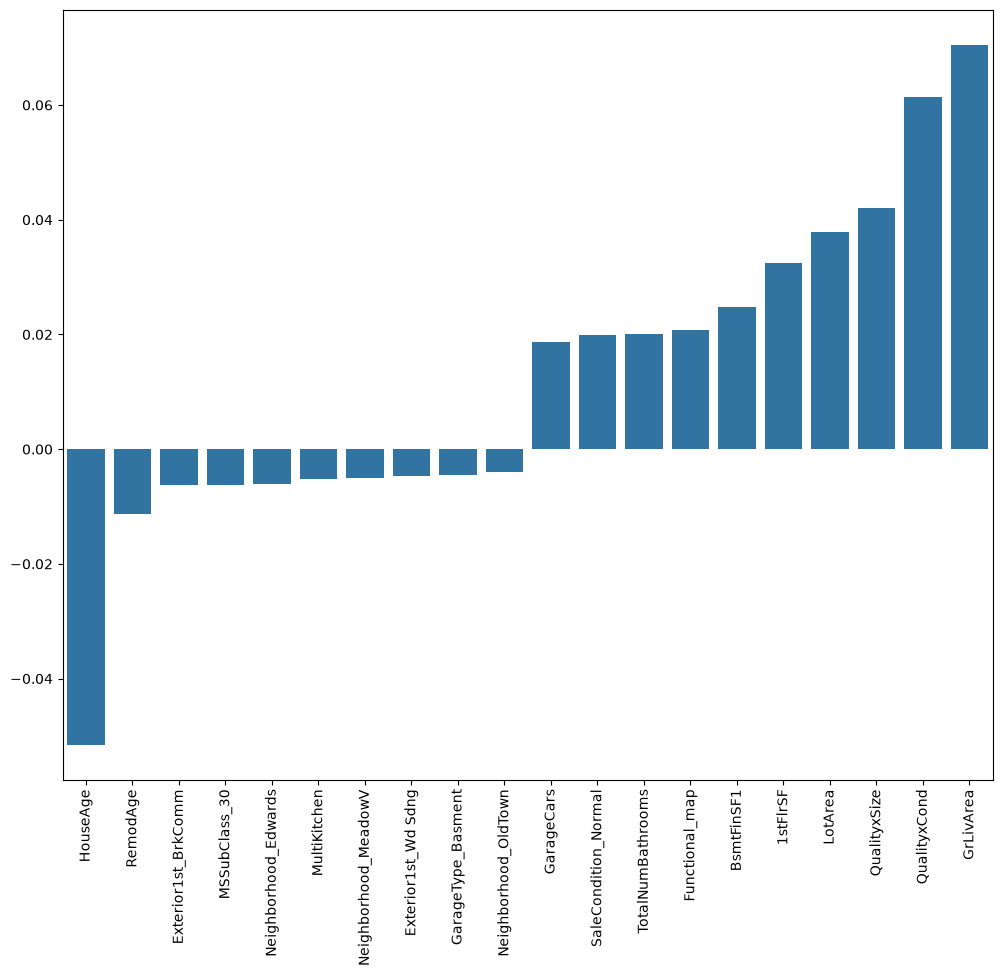

In [208]:
# Bar chart of those coefficients
plt.figure(figsize = (12,10))
sns.barplot(fe_imp)
plt.xticks(rotation = 90);

## 10. Stacking check

One more experiment: can the best models be combined into something better than the best single model? ElasticNet, XGBoost and Gradient Boosting (each at its tuned parameters from section 7) are stacked with a Ridge meta-model. A linear model and two tree models are used because models of different types are the most likely to make different mistakes.

How it works: `StackingRegressor` uses the same 5-fold split to build **out-of-fold predictions**, so each base model predicts houses it was not trained on. The Ridge meta-model learns from those predictions how much weight each base model deserves. The base models are then refitted on all training rows, and their predictions are blended with those weights. The stack is scored with the same CV as every other model, then once on the test set.

In [337]:
# Stacking: combine ElasticNet, XGB and GB with a Ridge meta-model

# 1. Pick the base models (diverse: one linear, two tree boosters)
base = [(name, clone(best_models[name])) for name in ["ElasticNet", "XGB", "GB"]]

# 2. Stack them. The meta-model learns how much to trust each one.
#    StackingRegressor builds the out-of-fold predictions itself (cv=cv).
stack = StackingRegressor(
    estimators=base,
    final_estimator=RidgeCV(alphas=np.logspace(-3, 2, 20)),
    cv=cv,
    n_jobs=-1,
)

# 3. Score it on the same folds as everything else (RMSLE, log scale)
scores = -cross_val_score(stack, X_train, y_train_log, cv=cv,
                          scoring="neg_root_mean_squared_error", n_jobs=-1)
print(f"Stack CV RMSLE: {scores.mean():.4f} +/- {scores.std():.4f}")

# 4. Fit once and check the test set (convert back to dollars)
stack.fit(X_train, y_train_log)
pred = np.expm1(stack.predict(X_test))
print("Test RMSE ($):", np.sqrt(mean_squared_error(np.expm1(y_test_log), pred)))
print("Meta weights:", dict(zip([n for n, _ in base], stack.final_estimator_.coef_.round(3))))

Stack CV RMSLE: 0.1093 +/- 0.0053
Test RMSE ($): 18270.95247941324
Meta weights: {'ElasticNet': np.float64(0.519), 'XGB': np.float64(0.411), 'GB': np.float64(0.09)}


**Result.** The stack's CV RMSLE is 0.1093 (`cv_std` 0.0053), against 0.1131 (`cv_std` 0.0046) for ElasticNet. The gap of about 0.004 is smaller than the fold standard deviation, so it is **not significant**: the stack is treated as a tie with the top group, not as a new winner. Its test RMSE is $18,271, against $18,796 for ElasticNet. With 292 test houses a difference of about $500 is not reliable either.

The meta-model gave most of the weight to ElasticNet (0.519) and XGBoost (0.411), and little to Gradient Boosting (0.090). The weights add up to about 1.02. This suggests the linear model and the tree models complement each other, and that Gradient Boosting adds little once XGBoost is included. Whether the models' errors are actually correlated was not checked.

Not done: a fold-by-fold comparison of the stack and ElasticNet, and a stack with fewer base models.

## 11. Conclusion and limitations

**Final results** (5-fold CV on 1,165 training houses; test set of 292 houses; mean training price about $180,074)

| Model | CV RMSLE | cv_std | Test RMSE | % of mean price | Test MAE | Test R² |
|---|---|---|---|---|---|---|
| ElasticNet | 0.1131 | 0.0046 | $18,796 | 10.4% | $13,863 | 0.943 |
| XGBoost | 0.1136 | 0.0074 | $19,937 | 11.1% | $13,692 | 0.936 |
| Gradient Boosting | 0.1173 | 0.0068 | $20,454 | 11.4% | $14,380 | 0.933 |
| Random Forest | 0.1300 | 0.0067 | $24,381 | 13.5% | $16,046 | 0.904 |
| AdaBoost | 0.1343 | 0.0043 | $24,508 | 13.6% | $16,453 | 0.903 |
| SVR | 0.1513 | 0.0039 | $40,361 | 22.4% | $20,317 | 0.737 |
| Decision Tree | 0.1727 | 0.0107 | $32,409 | 18.0% | $22,402 | 0.831 |
| KNN | 0.1826 | 0.0099 | $42,522 | 23.6% | $27,158 | 0.709 |

**What this shows**

- **A top group of three.** ElasticNet, XGBoost and Gradient Boosting are tied on cross-validation (0.1131, 0.1136 and 0.1173, with `cv_std` of 0.005 to 0.007), and they are also the three best on the test set (RMSE about $18.8k to $20.5k, R² 0.93 to 0.94). ElasticNet has the lowest test RMSE and the highest R², XGBoost the lowest test MAE. The differences between them are small, so no ranking inside the group is claimed.
- **Stacking did not separate from the best single model.** A Ridge meta-model over ElasticNet, XGBoost and Gradient Boosting gave a CV RMSLE of 0.1093 (`cv_std` 0.0053), about 0.004 (roughly 3%) lower than ElasticNet's 0.1131 (`cv_std` 0.0046). That gap is smaller than the fold standard deviation, so it is **not significant** and the stack is treated as a tie with the top group. Its test RMSE was $18,271 (10.1% of the mean price) against $18,796 for ElasticNet, a difference too small to rely on with 292 test houses. The meta-model weights were ElasticNet 0.519, XGBoost 0.411 and Gradient Boosting 0.090. ElasticNet remains the simplest model that matches the best score.
- **Random Forest and AdaBoost** are next, clearly behind the top group in CV (0.130 and 0.134, outside one `cv_std` of the best) with a test RMSE of about $24.4k to $24.5k.
- **SVR, Decision Tree and KNN** are the weakest (CV 0.151 to 0.183). SVR's test RMSE ($40.4k) is much higher than its test RMSLE (0.156) would suggest, which points to a few large dollar errors, probably on expensive houses. This was not investigated.
- **A regularised linear model matched the boosted trees.** The best ElasticNet uses `alpha` of about 0.0045 and `l1_ratio` 0.9. Its largest coefficients are `QualityxSize` (+0.10), `GrLivArea` (+0.048), `QualityxCond` (+0.043), `LotArea` (+0.037) and `1stFlrSF` (+0.035), and the largest negative ones are `HouseAge` (-0.046) and `RemodAge` (-0.011). No test was run to measure how much each engineered feature contributes, and correlated features share credit.
- **No before/after comparison was run** for the individual changes (ordinal encoding, the `GarageAge` definition, the outlier removal, the training-only `LotFrontage` fill), so their separate effects are not measured.

**Limitations**

- **Small test set.** 292 houses, so small differences between models are not reliable. Models were chosen on cross-validation.
- **CV to test gap.** For the top three, the test RMSLE (0.121, 0.125, 0.128) is 0.008 to 0.011 higher than the CV RMSLE. A harder test split, or a CV score that is slightly optimistic because it is the best of many tried settings, could both explain this.
- **Search budget.** The random searches used 30 draws per model, and whether they had converged was not checked.